# Домашнее задание 5. Градиентный спуск

В этом домашнем задании вы реализуете градиентный спуск для линейной регрессии, а также изучите, как он ведёт себя при разных параметрах и с разными функциями потерь.

In [87]:
from typing import Iterable, List

import matplotlib.pyplot as plt
import numpy as np

## Часть 1. Градиентный спуск (5 баллов)

Для начала давайте вспомним самый простой функционал ошибки, который мы применяем в задаче регрессии — **Mean Squared Error (MSE)**:

$$
Q(w, X, y) = \frac{1}{\ell} \sum\limits_{i=1}^\ell (\langle x_i, w \rangle - y_i)^2
$$

где $x_i$ — это $i$-ый объект датасета, $y_i$ — правильный ответ для $i$-го объекта, а $w$ — веса нашей линейной модели.

Как мы помним, для линейной модели его можно записать в матричном виде вот так:

$$
Q(w, X, y) = \frac{1}{\ell} || Xw - y ||^2
$$

где $X$ — это матрица объекты-признаки, а $y$ — вектор правильных ответов.

Чтобы воспользоваться методом градиентного спуска, нам нужно посчитать градиент нашего функционала. Для MSE он будет выглядеть так:

$$
\nabla_w Q(w, X, y) = \frac{2}{\ell} X^T(Xw-y)
$$

Ниже приведён базовый класс `BaseLoss`, который мы будем использовать для реализации всех наших лоссов. Менять его **не нужно**. У него есть два абстрактных метода:
1. Метод `calc_loss`, который будет принимать на вход объекты `x`, правильные ответы `y` и веса `w` и вычислять значения лосса.
2. Метод `calc_grad`, который будет принимать на вход объекты `x`, правильные ответы `y` и веса `w` и вычислять градиент функции потерь по параметрам модели.

In [88]:
import abc


class BaseLoss(abc.ABC):
    """Базовый класс лосса"""

    @abc.abstractmethod
    def calc_loss(self, X: np.ndarray, y: np.ndarray, w: np.ndarray) -> float:
        """
        Функция для вычислений значения лосса
        :param X: np.ndarray размера (n_objects, n_features) с объектами датасета
        :param y: np.ndarray размера (n_objects,) с правильными ответами
        :param w: np.ndarray размера (n_features,) с весами линейной регрессии
        :return: число - значения функции потерь
        """
        raise NotImplementedError

    @abc.abstractmethod
    def calc_grad(self, X: np.ndarray, y: np.ndarray, w: np.ndarray) -> np.ndarray:
        """
        Функция для вычислений градиента лосса по весам w
        :param X: np.ndarray размера (n_objects, n_features) с объектами датасета
        :param y: np.ndarray размера (n_objects,) с правильными ответами
        :param w: np.ndarray размера (n_features,) с весами линейной регрессии
        :return: np.ndarray размера (n_features,) градиент функции потерь по весам w
        """
        raise NotImplementedError

Теперь давайте напишем реализацию этого абстрактного класса: Mean Squared Error лосс.

**Задание 1.1 (5/8 балла):** Реализуйте класс `MSELoss`.

Он должен вычислять лосс и градиент по формулам наверху.

In [89]:
class MSELoss(BaseLoss):
    def calc_loss(self, X: np.ndarray, y: np.ndarray, w: np.ndarray) -> float:
        """
        Функция для вычислений значения лосса
        :param X: np.ndarray размера (n_objects, n_features) с объектами датасета
        :param y: np.ndarray размера (n_objects,) с правильными ответами
        :param w: np.ndarray размера (n_features,) с весами линейной регрессии
        :return: число -- значения функции потерь
        """
        mse = 1/len(X) * (np.sum((np.dot(X, w) - y) ** 2))
        return mse

    def calc_grad(self, X: np.ndarray, y: np.ndarray, w: np.ndarray) -> np.ndarray:
        """
        Функция для вычислений градиента лосса по весам w
        :param X: np.ndarray размера (n_objects, n_features) с объектами датасета
        :param y: np.ndarray размера (n_objects,) с правильными ответами
        :param w: np.ndarray размера (n_features,) с весами линейной регрессии
        :return: np.ndarray размера (n_features,) градиент функции потерь по весам w
        """
        grad = 2/len(X) * np.dot(X.T, np.dot(X, w) - y)
        return grad

Теперь мы можем создать объект `MSELoss` и при помощи него вычислять значение нашей функции потерь и градиенты:

In [90]:
# Создадим объект лосса
loss = MSELoss()

# Создадим какой-то датасет
X = np.arange(200).reshape(20, 10)
y = np.arange(20)

# Создадим какой-то вектор весов
w = np.arange(10)

# Выведем значение лосса и градиента на этом датасете с этим вектором весов
print(loss.calc_loss(X, y, w))
print(loss.calc_grad(X, y, w))

# Проверка, что методы реализованы правильно
assert loss.calc_loss(X, y, w) == 27410283.5, "Метод calc_loss реализован неверно"
assert np.allclose(
    loss.calc_grad(X, y, w),
    np.array(
        [
            1163180.0,
            1172281.0,
            1181382.0,
            1190483.0,
            1199584.0,
            1208685.0,
            1217786.0,
            1226887.0,
            1235988.0,
            1245089.0,
        ]
    ),
), "Метод calc_grad реализован неверно"
print("Всё верно!")

27410283.5
[1163180. 1172281. 1181382. 1190483. 1199584. 1208685. 1217786. 1226887.
 1235988. 1245089.]
Всё верно!


Теперь когда у нас есть всё для вычисления градиента, давайте напишем наш градиентный спуск. Напомним, что формула для одной итерации градиентного спуска выглядит следующим образом:

$$
w^{t+1} = w^{t} - \eta \nabla_{w} Q(w^{t}, X, y)
$$

Где $w^t$ — значение вектора весов на $t$-ой итерации, а $\eta$ — параметр learning rate, отвечающий за размер шага.

**Задание 1.2 (5/8 балла):** Реализуйте функцию `gradient_descent`.

Функция должна принимать на вход начальное значение весов линейной модели `w_init`, матрицу объектов-признаков `X`,
вектор правильных ответов `y`, объект функции потерь `loss`, размер шага `lr` и количество итераций `n_iterations`.

Функция должна реализовывать цикл, в котором происходит шаг градиентного спуска (градиенты берутся из `loss` посредством вызова метода `calc_grad`) по формуле выше, и возвращать
траекторию спуска (список из новых значений весов на каждом шаге).

In [91]:
def gradient_descent(
    w_init: np.ndarray,
    X: np.ndarray,
    y: np.ndarray,
    loss: BaseLoss,
    lr: float,
    n_iterations: int = 100000,
) -> List[np.ndarray]:
    """
    Функция градиентного спуска
    :param w_init: np.ndarray размера (n_feratures,) - начальное значение вектора весов
    :param X: np.ndarray размера (n_objects, n_features) - матрица объекты-признаки
    :param y: np.ndarray размера (n_objects,) - вектор правильных ответов
    :param loss: Объект подкласса BaseLoss, который умеет считать градиенты при помощи loss.calc_grad(X, y, w)
    :param lr: float -- параметр величины шага, на который нужно домножать градиент
    :param n_iterations: int --сколько итераций делать
    :return: Список из n_iterations объектов np.ndarray размера (n_features,) - история весов на каждом шаге
    """
    w = w_init.copy() # чтобы при изменении w w_init не менялось
    w_list = [] # создаем пустой список для всех значений w
    for i in range(n_iterations):
      w -= lr * loss.calc_grad(X, y, w) # обновляем w
      w_list.append(w.copy()) # добавляем значение w в историю значений
    return w_list

Теперь создадим синтетический датасет и функцию, которая будет рисовать траекторию градиентного спуска по истории.

In [92]:
# Создаём датасет из двух переменных и реального вектора зависимости w_true

np.random.seed(1337)

n_features = 2
n_objects = 300
batch_size = 10
num_steps = 43

w_true = np.random.normal(size=(n_features,))

X = np.random.uniform(-5, 5, (n_objects, n_features))
X *= (np.arange(n_features) * 2 + 1)[np.newaxis, :] # разные масштабы признаков
y = X.dot(w_true) + np.random.normal(0, 1, (n_objects))
w_init = np.random.uniform(-2, 2, (n_features))

print(X.shape)
print(y.shape)

(300, 2)
(300,)


In [93]:
loss = MSELoss()
w_list = gradient_descent(w_init, X, y, loss, 0.01, 100)
print(loss.calc_loss(X, y, w_list[0]))
print(loss.calc_loss(X, y, w_list[-1]))

155.2625821435194
0.8670644395649493


In [94]:
def plot_gd(w_list: Iterable, X: np.ndarray, y: np.ndarray, loss: BaseLoss):
    """
    Функция для отрисовки траектории градиентного спуска
    :param w_list: Список из объектов np.ndarray размера (n_features,) -- история весов на каждом шаге
    :param X: np.ndarray размера (n_objects, n_features) -- матрица объекты-признаки
    :param y: np.ndarray размера (n_objects,) -- вектор правильных ответов
    :param loss: Объект подкласса BaseLoss, который умеет считать лосс при помощи loss.calc_loss(X, y, w)
    """
    w_list = np.array(w_list)
    meshgrid_space = np.linspace(-2, 2, 100)
    A, B = np.meshgrid(meshgrid_space, meshgrid_space)

    levels = np.empty_like(A)
    for i in range(A.shape[0]):
        for j in range(A.shape[1]):
            w_tmp = np.array([A[i, j], B[i, j]])
            levels[i, j] = loss.calc_loss(X, y, w_tmp)

    plt.figure(figsize=(15, 6))
    plt.title("GD trajectory")
    plt.xlabel(r"$w_1$")
    plt.ylabel(r"$w_2$")
    plt.xlim(w_list[:, 0].min() - 0.1, w_list[:, 0].max() + 0.1)
    plt.ylim(w_list[:, 1].min() - 0.1, w_list[:, 1].max() + 0.1)
    plt.gca().set_aspect("equal")

    # Отображение уровня функции потерь
    CS = plt.contour(
        A, B, levels, levels=np.logspace(0, 1, num=20), cmap=plt.cm.rainbow_r
    )
    CB = plt.colorbar(CS, shrink=0.8, extend="both")

    # Отображение траектории спуска
    plt.scatter(w_list[:, 0], w_list[:, 1])
    plt.plot(w_list[:, 0], w_list[:, 1])

    plt.show()

**Задание 1.3 (5/8 балла):** При помощи функций `gradient_descent` и  `plot_gd` нарисуйте траекторию градиентного спуска для разных значений длины шага (параметра `lr`). Используйте четыре и более различных значений для `lr`.

Сделайте и опишите свои выводы о том, как параметр `lr` влияет на поведение градиентного спуска.

Подсказки:
* Функция `gradient_descent` возвращает историю весов, которую нужно подать в функцию `plot_gd`.
* Хорошие значения для `lr` могут лежать в промежутке от 0.0001 до 0.1.

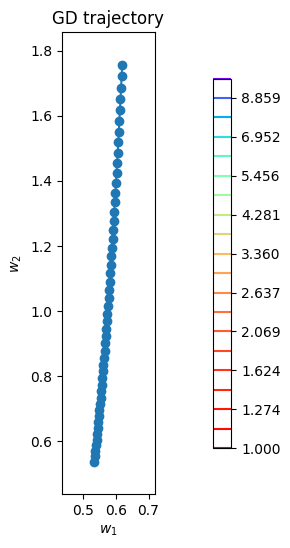

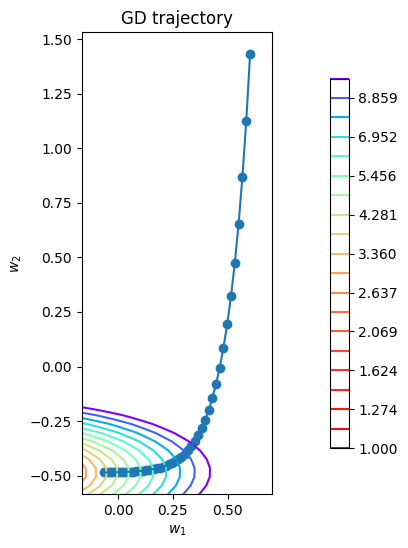

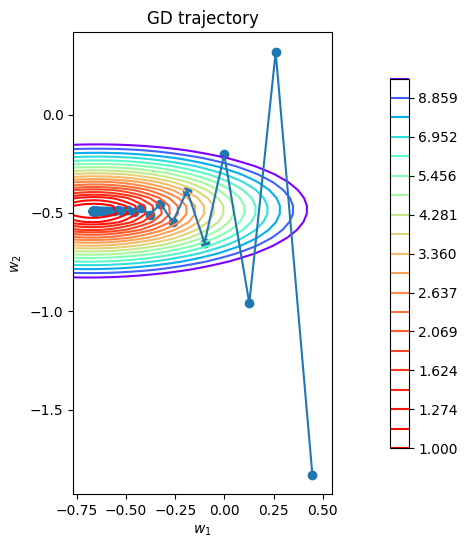

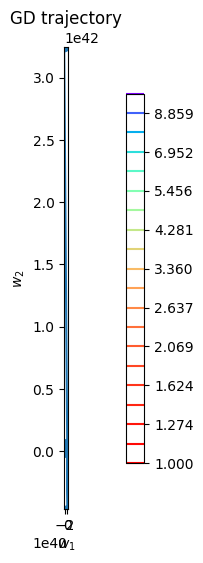

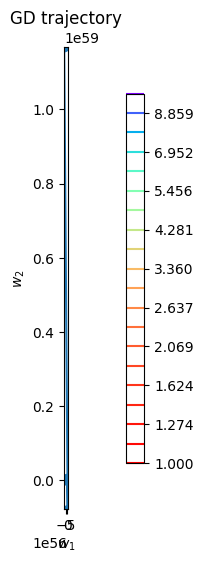

In [95]:
for lr in [0.0001, 0.001, 0.01, 0.05, 0.1]:
    w_list = gradient_descent(w_init, X, y, loss, lr=lr, n_iterations=50)
    plot_gd(w_list, X, y, loss)

**Вывод:** lr = 0.0001 - слишком маленький, тк за 50 итераций мы практически не сдвинулись с места (очень слабо приблизились к минимуму). При lr = 0.001 ситуация улучшается, тк мы шагаем бОльшими шагами, но все еще не достигаем минимума. lr = 0.01 - оптимален, сходимся к экстремуму: чем ближе - тем плавнее. При lr = 0,5 и больше - шаг слишком большой, поэтому перепрыгивает минимум и график становится узким

Теперь реализуем стохастический градиентный спуск.

**Задание 1.4 (5/8 балла):** Реализуйте функцию `stochastic_gradient_descent`.

Функция должна принимать все те же параметры, что и функция `gradient_descent`, но ещё параметр `batch_size`, отвечающий за размер батча.

Функция должна как и раньше реализовывать цикл, в котором происходит шаг градиентного спуска, но на каждом шаге считать градиент не по всей выборке `X`, а только по случайно выбранной части.

Подсказка: для выбора случайной части можно использовать [`np.random.choice`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.choice.html) с правильным параметром `size`, чтобы выбрать случайные индексы, а потом проиндексировать получившимся массивом массив `X`:
```
batch_indices = np.random.choice(X.shape[0], size=batch_size, replace=False)
batch = X[batch_indices]
```

In [96]:
def stochastic_gradient_descent(
    w_init: np.ndarray,
    X: np.ndarray,
    y: np.ndarray,
    loss: BaseLoss,
    lr: float,
    batch_size: int,
    n_iterations: int = 1000,
) -> List[np.ndarray]:
    """
    Функция градиентного спуска
    :param w_init: np.ndarray размера (n_feratures,) -- начальное значение вектора весов
    :param X: np.ndarray размера (n_objects, n_features) -- матрица объекты-признаки
    :param y: np.ndarray размера (n_objects,) -- вектор правильных ответов
    :param loss: Объект подкласса BaseLoss, который умеет считать градиенты при помощи loss.calc_grad(X, y, w)
    :param lr: float -- параметр величины шага, на который нужно домножать градиент
    :param batch_size: int -- размер подвыборки, которую нужно семплировать на каждом шаге
    :param n_iterations: int -- сколько итераций делать
    :return: Список из n_iterations объектов np.ndarray размера (n_features,) -- история весов на каждом шаге
    """

    w = w_init.copy() # из №1.2
    w_list = []
    for i in range(n_iterations):
      batch_indices = np.random.choice(X.shape[0], size=batch_size, replace=False) # выбираем рандомную подвыборку
      batch_x, batch_y = X[batch_indices], y[batch_indices] # берем только нужные строким
      # далее все аналогично №1.2
      w -= lr * loss.calc_grad(batch_x, batch_y, w)
      w_list.append(w.copy())
    return w_list

**Задание 1.5 (5/8 балла):** При помощи функций `stochastic_gradient_descent` и  `plot_gd` нарисуйте траекторию градиентного спуска для разных значений длины шага (параметра `lr`) и размера подвыборки (параметра `batch_size`). Используйте не менее четырёх разных значений для `lr` и `batch_size`.

Сделайте и опишите свои выводы о том, как параметры  `lr` и `batch_size` влияют на поведение стохастического градиентного спуска. Как отличается поведение стохастического градиентного спуска от обычного? Что происходит при малых и больших `batch_size`?

Обратите внимание, что в нашем датасете всего 300 объектов, так что `batch_size` больше этого числа не будет иметь смысла.

lr=0.001, batch_size=10


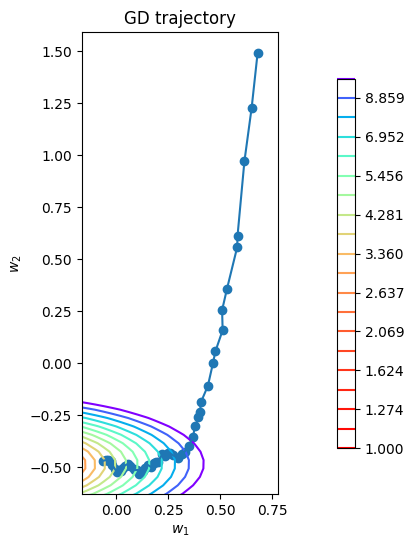

lr=0.001, batch_size=90


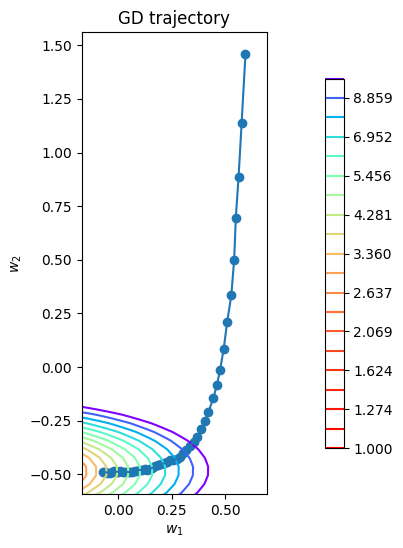

lr=0.001, batch_size=180


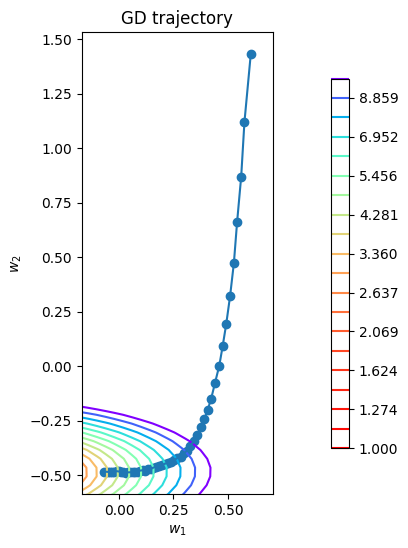

lr=0.001, batch_size=270


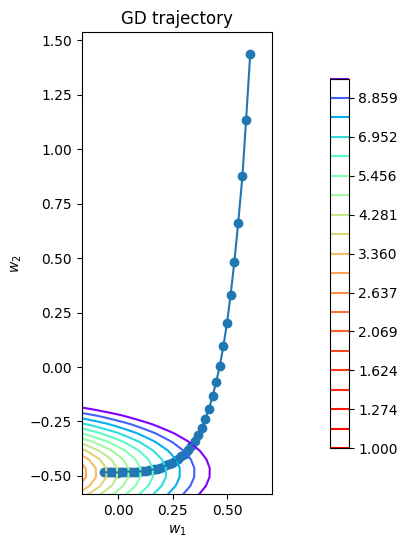

lr=0.005, batch_size=10


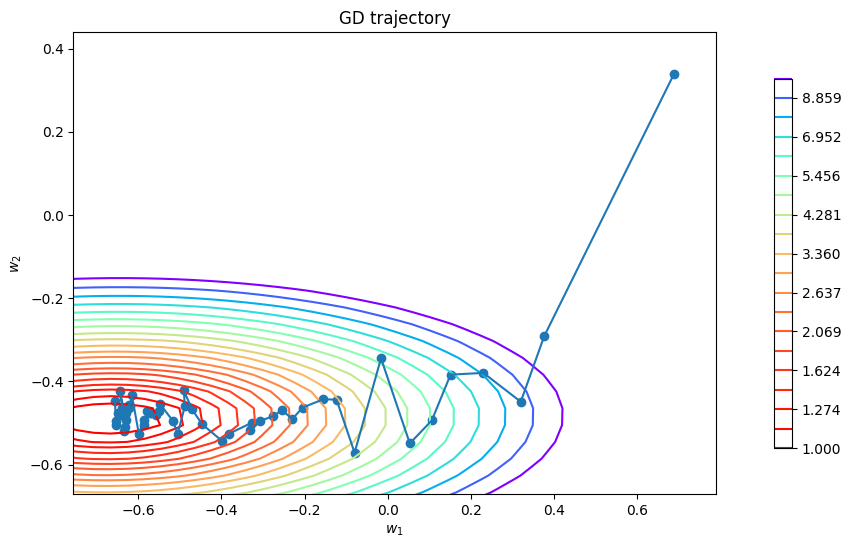

lr=0.005, batch_size=90


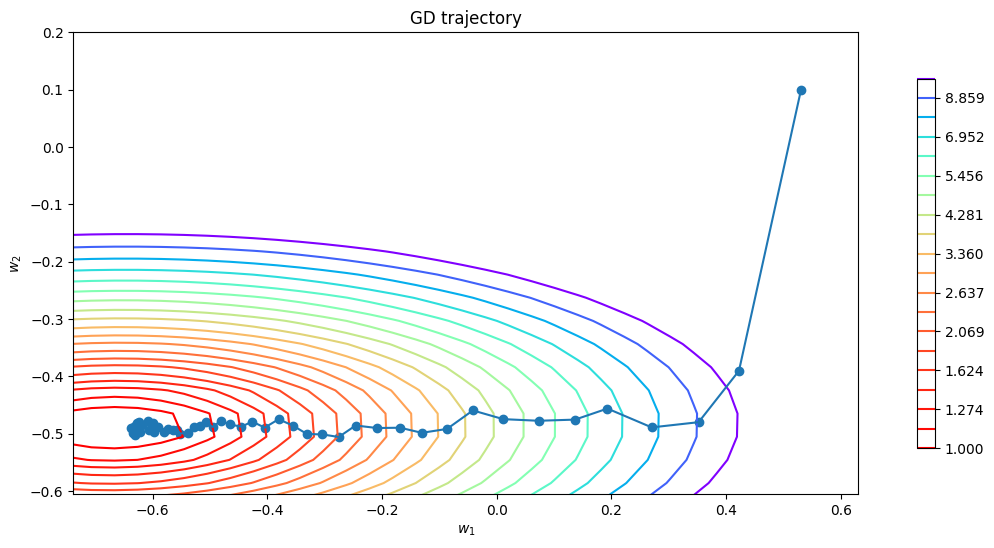

lr=0.005, batch_size=180


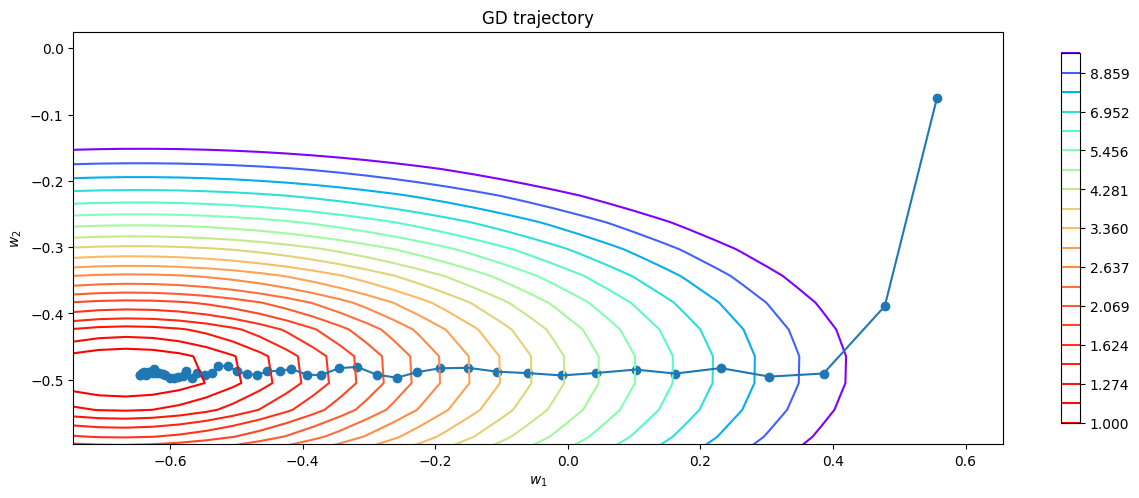

lr=0.005, batch_size=270


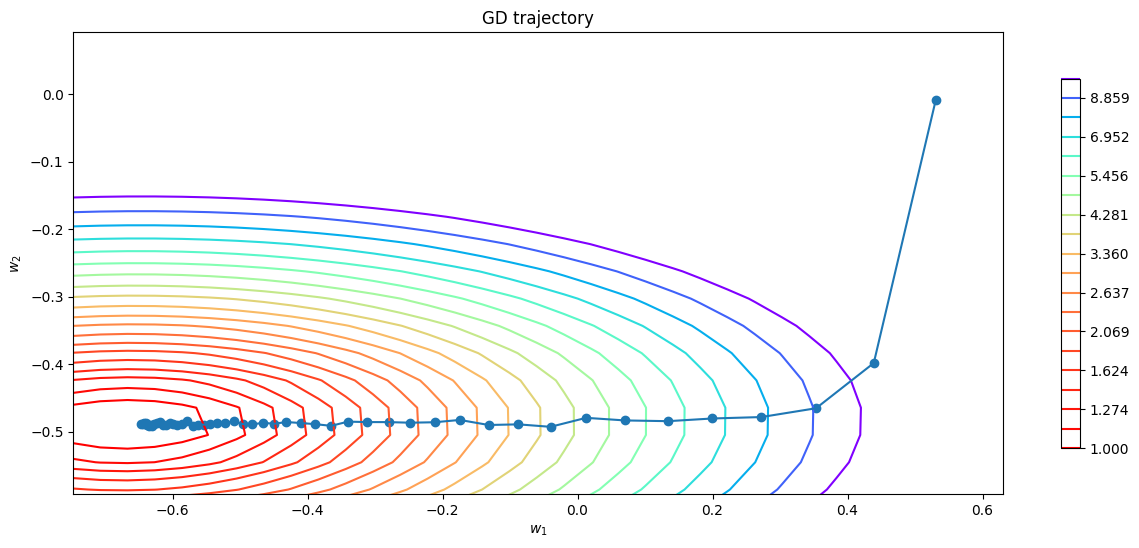

lr=0.01, batch_size=10


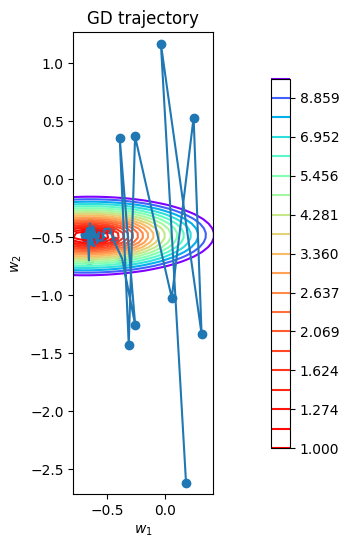

lr=0.01, batch_size=90


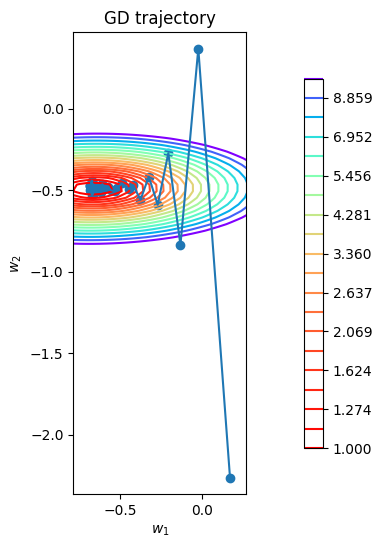

lr=0.01, batch_size=180


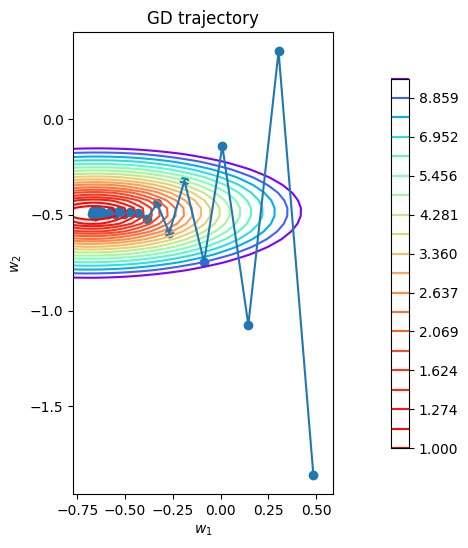

lr=0.01, batch_size=270


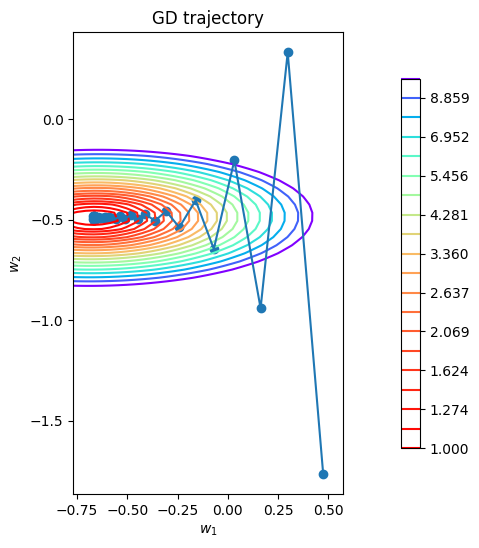

lr=0.05, batch_size=10


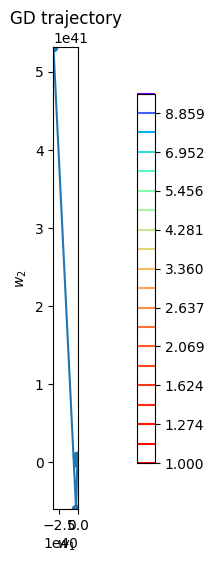

lr=0.05, batch_size=90


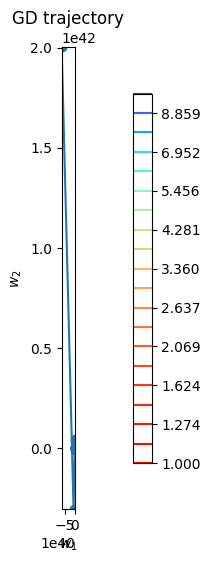

lr=0.05, batch_size=180


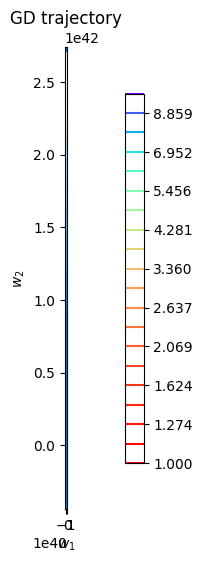

lr=0.05, batch_size=270


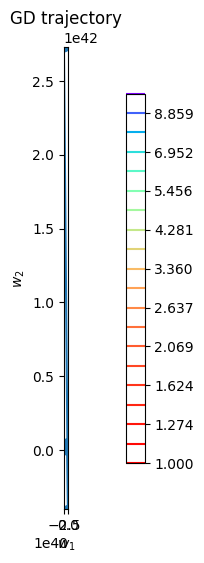

In [97]:
for lr in [0.001, 0.005, 0.01, 0.05]:
  for batch_size in [10, 90, 180, 270]:
    w_list = stochastic_gradient_descent(w_init, X, y, loss, lr=lr, batch_size=batch_size, n_iterations=50)
    print(f"lr={lr}, batch_size={batch_size}")
    plot_gd(w_list, X, y, loss)

**Вывод:** lr = 0.05 оказался слишком большим вне зависимости от величины подвыборки (как и в №1.3, график сузился, тк минимум перепрыгивается и не достигается). Рассмотрим оставшиеся графики. Заметим, что с ростом batch_size (при фиксированном значении lr), траектория градиентного спуска становится плавнее, особенно это заметно при переходе с batch_size=10 до batch_size=90. Что касается изменения lr, то так как шаг становится больше, то при больших значениях lr и batch_size, мы начинаем доходить до минимума. Например, при lr = 0.001 даже при самом большом значении batch_size, до минимума мы не доходим. Стохастический градиентный спуск в целом ведёт себя более хаотично по сравнению с обычным, но при больших batch_size его поведение становится похожим на обычный градиентный спуск.

Вы могли заметить, что поведение градиентного спуска, особенно стохастической версии, очень сильно зависит от размера шага.

Как правило, в начале спуска мы хотим делать большие шаги, чтобы поскорее подойти поближе к минимуму, а позже мы уже хотим делать шаги маленькие, чтобы точнее этого минимума достигнуть и не "перепрыгнуть" его.

Чтобы достичь такого поведения мы можем постепенно уменьшать длину шага с увеличением номера итерации. Сделать это можно, например, вычисляя на каждой итерации длину шага по следующей формуле:

$$
    \eta_t
    =
    \lambda
    \left(
        \frac{s_0}{s_0 + t}
    \right)^p
$$

где $\eta_t$ — длина шага на итерации $t$, $\lambda$ — начальная длина шага (параметр `lr` у нас), $s_0$ и $p$ — настраиваемые параметры.

**Задание 1.6 (5/8 балла):** Реализуйте функцию `stochastic_gradient_descent` на этот раз с затухающим шагом по формуле выше. Параметр $s_0$ возьмите равным 1. Параметр $p$ возьмите из нового аргумента функции `p`.

In [98]:
def stochastic_gradient_descent(
    w_init: np.ndarray,
    X: np.ndarray,
    y: np.ndarray,
    loss: BaseLoss,
    lr: float,
    batch_size: int,
    p: float,
    n_iterations: int = 1000,
) -> List[np.ndarray]:
    """
    Функция градиентного спуска
    :param w_init: np.ndarray размера (n_feratures,) - начальное значение вектора весов
    :param X: np.ndarray размера (n_objects, n_features) - матрица объекты-признаки
    :param y: np.ndarray размера (n_objects,) - вектор правильных ответов
    :param loss: Объект подкласса BaseLoss, который умеет считать градиенты при помощи loss.calc_grad(X, y, w)
    :param lr: float - параметр величины шага, на который нужно домножать градиент
    :param batch_size: int - размер подвыборки, которую нужно семплировать на каждом шаге
    :param p: float - значение степени в формуле затухания длины шага
    :param n_iterations: int - сколько итераций делать
    :return: Список из n_iterations объектов np.ndarray размера (n_features,) - история весов на каждом шаге
    """
    w = w_init.copy()
    w_list = []
    for t in range(n_iterations):
      n_t = lr * (1 / (1 + t)) ** p # используя формулу
      batch_indices = np.random.choice(X.shape[0], size=batch_size, replace=False)
      batch_x, batch_y = X[batch_indices], y[batch_indices]
      w -= n_t * loss.calc_grad(batch_x, batch_y, w)
      w_list.append(w.copy())
    return w_list

**Задание 1.7 (5/8 балла):** При помощи новой функции `stochastic_gradient_descent` и функции `plot_gd` нарисуйте траекторию градиентного спуска для разных значений параметра `p`. Используйте не менее четырёх разных значений для `p`. Хорошими могут быть значения, лежащие в промежутке от 0.1 до 1.
Параметр `lr` возьмите равным 0.01, а параметр `batch_size` равным 10.

Сделайте и опишите свои выводы о том, как параметр `p` влияет на поведение стохастического градиентного спуска. Что происходит при маленьком или большом значении p?

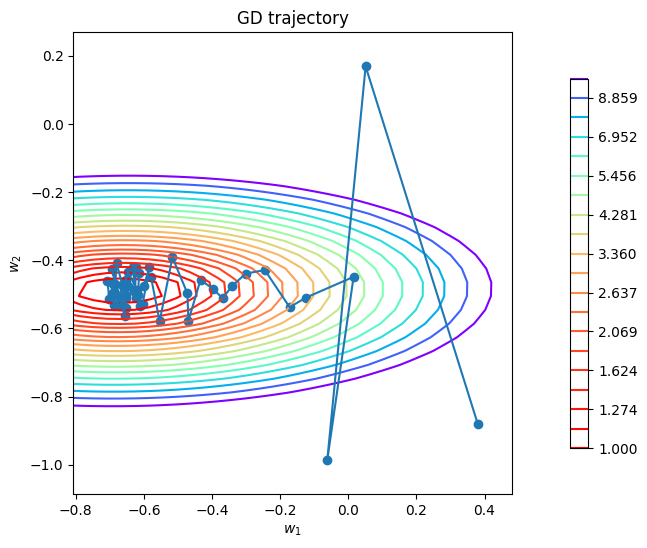

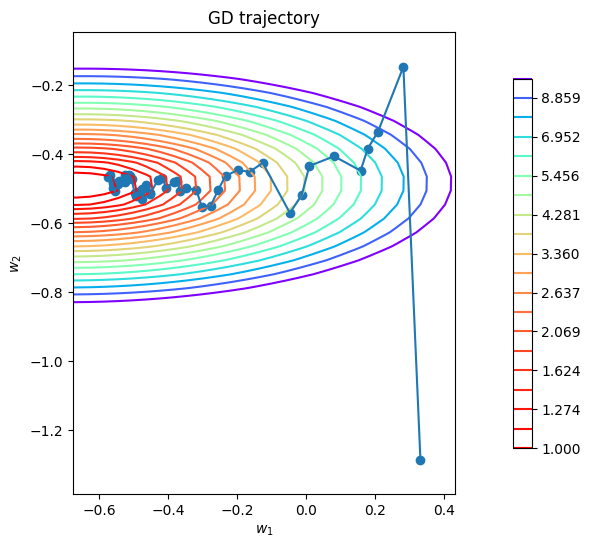

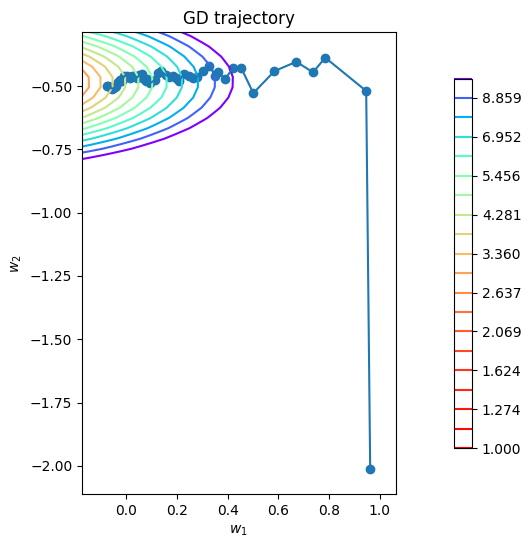

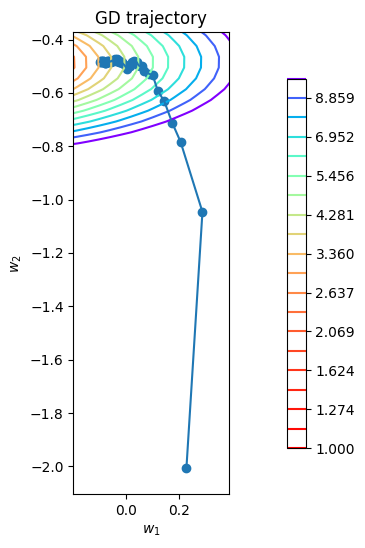

In [99]:
for p in [0.1, 0.4, 0.7, 1]:
  w_list = stochastic_gradient_descent(w_init, X, y, loss, lr=0.01, batch_size=10, p=p, n_iterations=50)
  plot_gd(w_list, X, y, loss)

**Вывод:** p влияет на шум и размашистость траектории SGD. При маленьких p заметно больше колебаний, хаотичности, так как шаг затухает медленнее (долго остается большим). При этом движение к минимуму происходит быстрее. С ростом p путь становится более гладким, а шаги - менее размашистыми (шаг затухает быстрее, быстрее становится маленьким), движение замедляется, на последних 3 графиках минимум не достигается.


**Задание 1.8 (5/8 балла):** Сравните сходимость обычного градиентного спуска и стохастичекой версии:
Нарисуйте график зависимости значения лосса (его можно посчитать при помощи метода `calc_loss`, используя $x$ и $y$ из датасета и $w$ с соответствующей итерации) от номера итерации для траекторий, полученных при помощи обычного и стохастического градиентного спуска с одинаковыми параметрами. Параметр `batch_size` возьмите равным 10.

Видно ли на данном графике преимущество SGD? Почему?

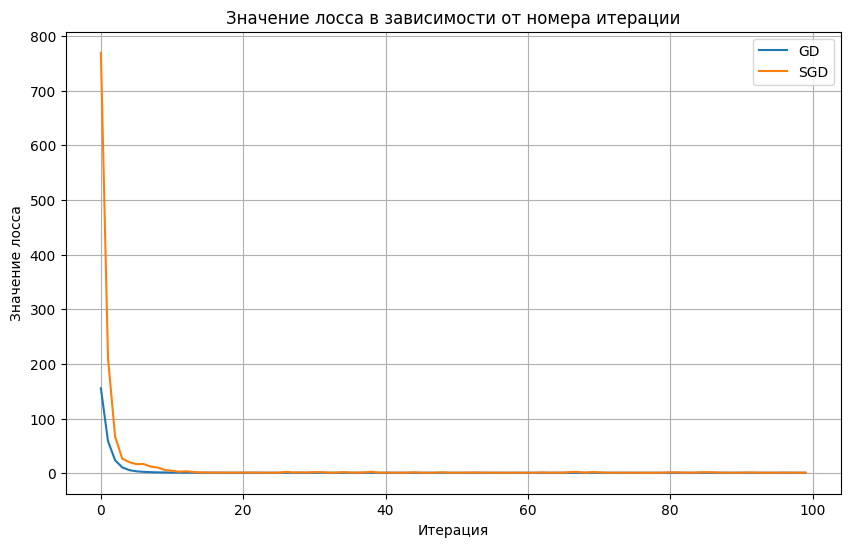

In [100]:
w_gd = w_init.copy()
w_gd_list = []
for _ in range(100):
    grad = loss.calc_grad(X, y, w_gd)
    w_gd -= 0.01 * grad
    w_gd_list.append(loss.calc_loss(X, y, w_gd))

w_sgd = w_init.copy()
w_sgd_list = []
for _ in range(100):
    batch_indices = np.random.choice(X.shape[0], size=10, replace=False)
    X_batch, y_batch = X[batch_indices], y[batch_indices]
    grad = loss.calc_grad(X_batch, y_batch, w_sgd)
    w_sgd -= 0.01 * grad
    w_sgd_list.append(loss.calc_loss(X, y, w_sgd))

plt.figure(figsize=(10, 6))
plt.title("Значение лосса в зависимости от номера итерации")
plt.plot(w_gd_list, label='GD')
plt.plot(w_sgd_list, label='SGD')
plt.xlabel('Итерация')
plt.ylabel('Значение лосса')
plt.legend()
plt.grid()
plt.show()

**Вывод:** На графике видно преимущество SGD, так как, несмотря на то, что ошибка убывает с шумом (больше колебаний, менее плавная линия), он быстрее уменьшает значение функции потерь на первых итерациях, так как градиент считается по случайной подвыборке (приближенная сходимость), а не по всем объектам. Однако дальше сходимость замедляется и наблюдаются совсем незначительные колебания.

## Часть 2. Линейная регрессия (5 баллов)

Теперь давайте напишем наш класс для линейной регрессии. Он будет использовать интерфейс, знакомый нам из библиотеки `sklearn`.

В методе `fit` мы будем подбирать веса `w` при помощи градиентного спуска нашим методом `gradient_descent`.

В методе `predict` мы будем применять нашу регрессию к датасету.

**Задание 2.1 (5/8 балла):** Допишите код в методах `fit` и `predict` класса `LinearRegression`.

В методе `fit` вам нужно как-то инициализировать веса `w`, применить `gradient_descent` и сохранить последнюю `w` из траектории.

В методе `predict` вам нужно применить линейную регрессию и вернуть вектор ответов.

Обратите внимание, что объект лосса передаётся в момент инициализации и хранится в `self.loss`. Его нужно использовать в `fit` для `gradient_descent`.

In [158]:
class LinearRegression:
    def __init__(self, loss: BaseLoss, lr: float = 0.1) -> None:
        self.loss = loss
        self.lr = lr

    def fit(self, X: np.ndarray, y: np.ndarray) -> "LinearRegression":
        X = np.asarray(X)
        y = np.asarray(y)
        # Добавляем столбец из единиц для константного признака
        X = np.hstack([X, np.ones([X.shape[0], 1])])
        n_features = X.shape[1]
        w_init = np.zeros(n_features)
        w_list = gradient_descent(w_init, X, y, loss=self.loss, lr=self.lr, n_iterations=1000)
        self.w = w_list[-1]
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        # Проверяем, что регрессия обучена, то есть, что был вызван fit и в нём был установлен атрибут self.w
        assert hasattr(self, "w"), "Linear regression must be fitted first"
        # Добавляем столбец из единиц для константного признака
        X = np.hstack([X, np.ones([X.shape[0], 1])])
        res = np.dot(X, self.w)
        return res

Теперь у нас есть наш класс линейной регрессии. Более того, мы можем управлять тем, какую функцию потерь мы оптимизируем, просто передавая разные классы в параметр `loss` при инициализации.

Пока у нас нет никаких классов кроме `MSELoss`, но скоро они появятся.

Для `MSELoss` мы бы создавали наш объект линейной регрессии, например, так:

In [159]:
linear_regression = LinearRegression(MSELoss())

Применим нашу регрессию на реальном датасете. Загрузим датасет с машинами, который был у вас на семинарах:

In [160]:
import pandas as pd

X_raw = pd.read_csv(
    "cars_data.csv",
    header=None,
    na_values=["?"],
    skiprows=1,
    index_col=0
)
X_raw = X_raw[~X_raw[26].isna()].reset_index(drop=True)
X_raw.head()

,1,2,3,4,5,6,7,8,9,10,...,17,18,19,20,21,22,23,24,25,26
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


In [161]:
y = X_raw[26]
X_raw = X_raw.drop(26, axis=1)

**Задание 2.2 (5/8 балла):** Как обычно обработайте датасет всеми нужными методами, чтобы на нём можно было обучать линейную регрессию:

* Разделите датасет на обучающую и тестовую выборку
* Заполните пропуски
* Нормализуйте числовые признаки
* Закодируйте категориальные переменные

In [162]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
np.random.seed(42) # разделим на test и train
X_train, X_test, y_train, y_test = train_test_split(X_raw, y, test_size=0.3)
# создадим маски:
float_mask = (X_train.dtypes == "float64").values
int_mask = (X_train.dtypes == "int64").values
cat_mask = (X_train.dtypes == "object").values
# для числовых:
X_train_real = X_train[X_train.columns[float_mask | int_mask]]
X_test_real = X_test[X_test.columns[float_mask | int_mask]]
# для категориальных заполняем пустыми строками (с семинара):
X_train_cat = X_train[X_train.columns[cat_mask]].fillna("")
X_test_cat = X_test[X_test.columns[cat_mask]].fillna("")
# заполним пропуски в числовых средним значением:
mis_replacer = SimpleImputer(strategy="mean") # взято с семинара
X_train_real_filled = pd.DataFrame(mis_replacer.fit_transform(X_train_real), columns=X_train_real.columns, index=X_train_real.index)
X_test_real_filled = pd.DataFrame(mis_replacer.transform(X_test_real), columns=X_test_real.columns, index=X_test_real.index)
# склеиваем в две таблицы:
X_train_clean = pd.concat([X_train_real_filled, X_train_cat], axis=1)
X_test_clean = pd.concat([X_test_real_filled, X_test_cat], axis=1)
# кодируем категориальные признаки и приводим названия к типу строки:
X_train_clean = pd.get_dummies(X_train_clean, drop_first=True)
X_test_clean = pd.get_dummies(X_test_clean, drop_first=True)
X_train_clean.columns = X_train_clean.columns.astype(str)
X_test_clean.columns = X_test_clean.columns.astype(str)
X_test_clean = X_test_clean.reindex(columns=X_train_clean.columns, fill_value=0) # выравниваем признаки test под train
scaler = StandardScaler() # стандартизируем
X_train_scaled = scaler.fit_transform(X_train_clean) # обучаем и применяем на train
X_test_scaled = scaler.transform(X_test_clean) # применяем на test

**Задание 2.3 (5/8 балла):** Обучите написанную вами линейную регрессию на обучающей выборке

In [163]:
model = LinearRegression(loss=MSELoss(), lr=0.09)
model.fit(X_train_scaled, y_train)

**Задание 2.4 (5/8 балла):** Посчитайте ошибку обученной регрессии на обучающей и тестовой выборке при помощи метода `mean_squared_error` из `sklearn.metrics`.

In [164]:
from sklearn.metrics import mean_squared_error
# делаем предсказание
y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)
# считаем ошибку
mse_train = mean_squared_error(y_train, y_train_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
print(f'MSE на train: {mse_train}')
print(f'MSE на test: {mse_test}')

MSE на train: 1444732.3107464935
MSE на test: 6621590.034981412


Наша модель переобучилась. Давайте как обычно в такой ситуации добавим к ней L2 регуляризацию. Для этого нам нужно написать новый класс лосса.

Формула функции потерь для MSE с L2 регуляризацией выглядит так:
$$
Q(w, X, y) = \frac{1}{\ell} \sum\limits_{i=1}^\ell (\langle x_i, w \rangle - y_i)^2 + \lambda ||w||^2
$$

Или в матричном виде:

$$
Q(w, X, y) = \frac{1}{\ell} || Xw - y ||^2 + \lambda ||w||^2
$$

Где $\lambda$ — коэффициент регуляризации.

Градиент выглядит так:

$$
\nabla_w Q(w, X, y) = \frac{2}{\ell} X^T(Xw-y) + 2 \lambda w
$$

**Задание 2.5 (5/8 балла):** Реализуйте класс `MSEL2Loss`.

Он должен вычислять лосс и градиент по формулам выше.

Подсказка: обратите внимание, что последний элемент вектора `w` — это bias (в классе `LinearRegression` к матрице `X` добавляется колонка из единиц — константный признак). Как мы знаем из лекций и семинаров, bias регуляризовать не нужно. Поэтому не забудьте убрать последний элемент из `w` при подсчёте слагаемого $\lambda||w||^2$ в `calc_loss` и занулить его при подсчёте слагаемого $2 \lambda w$ в `calc_grad`.

In [165]:
class MSEL2Loss(BaseLoss):
    def __init__(self, coef: float = 1.0):
        """
        :param coef: коэффициент регуляризации (лямбда в формуле)
        """
        self.coef = coef

    def calc_loss(self, X: np.ndarray, y: np.ndarray, w: np.ndarray) -> float:
        """
        Функция для вычислений значения лосса
        :param X: np.ndarray размера (n_objects, n_features) с объектами датасета. Последний признак константный.
        :param y: np.ndarray размера (n_objects,) с правильными ответами
        :param w: np.ndarray размера (n_features,) с весами линейной регрессии. Последний вес -- bias.
        :output: число -- значения функции потерь
        """
        w_need = w[:-1] # убираем последний вес
        mse_l2 = 1/len(y) * np.sum((np.dot(X, w) - y) ** 2) + self.coef * np.sum(w_need ** 2)
        return mse_l2

    def calc_grad(self, X: np.ndarray, y: np.ndarray, w: np.ndarray) -> np.ndarray:
        """
        Функция для вычислений градиента лосса по весам w
        :param X: np.ndarray размера (n_objects, n_features) с объектами датасета
        :param y: np.ndarray размера (n_objects,) с правильными ответами
        :param w: np.ndarray размера (n_features,) с весами линейной регрессии
        :output: np.ndarray размера (n_features,) градиент функции потерь по весам w
        """
        grad = 2/len(y) * np.dot(X.T, np.dot(X, w) - y)
        fine = 2 * self.coef * w
        fine[-1] = 0
        result_grad = grad + fine
        return result_grad

Теперь мы можем использовать лосс с l2 регуляризацией в нашей регрессии, например, так:

In [166]:
linear_regression = LinearRegression(MSEL2Loss(0.1))

**Задание 2.6 (5/8 балла):** Обучите регрессию с лоссом `MSEL2Loss`. Подберите хороший коэффициент регуляризации и добейтесь улучшения результата на тестовой выборке. Сравните результат на обучающей и тестовой выборке с регрессией без регуляризации.

In [167]:
for coef in [0.0001, 0.001, 0.01, 0.05, 0.1, 1]:
  model = LinearRegression(loss=MSEL2Loss(coef=coef), lr=0.09)
  model.fit(X_train_scaled, y_train)
  y_train_pred = model.predict(X_train_scaled)
  y_test_pred = model.predict(X_test_scaled)
  mse_train = mean_squared_error(y_train, y_train_pred)
  mse_test = mean_squared_error(y_test, y_test_pred)
  print(f"coef={coef}, MSE на train = {mse_train}, MSE на test = {mse_test}")

coef=0.0001, MSE на train = 1446271.512652483, MSE на test = 6607743.659926052
coef=0.001, MSE на train = 1460866.971391465, MSE на test = 6497819.707965811
coef=0.01, MSE на train = 1625511.3680320948, MSE на test = 6160791.827793307
coef=0.05, MSE на train = 2070246.1916856042, MSE на test = 6652270.787460473
coef=0.1, MSE на train = 2364947.165487494, MSE на test = 7166681.96821049
coef=1, MSE на train = 1.8651902957368953e+50, MSE на test = 2.3269626650311537e+50


**Было:** на train: ~1444732, на test: ~6621590


**Стало:** на train: ~1625511, на test: ~6160792

**Вывод:** при L2-регуляризации удалось немного улучшить результат на тестовой выборке. Наименьшая ошибка на test достигается при coef=0.01, при этом ошибка на train немного увеличивается. При увеличении coef качество на test ухудшается. При coef = 1 происходит расходимость.

В нашем датасете могут быть выбросы. На семинаре вам рассказывали, что с выбросами хорошо помогает бороться Huber Loss. Вдали от нуля он работает как Mean Absolute Error и не реагирует на выбросы так сильно, как MSE. Давайте его реализуем и применим в нашей регрессии.

Напомним, что функция потерь Huber Loss'а  выглядит так:


$$
    Q(w, X, y) = \frac{1}{\ell} \sum\limits_{i=1}^\ell \phi_\varepsilon (\langle x_i, w \rangle - y_i)
$$
$$
    \phi_\varepsilon(z) = \begin{cases} \frac 1 2 z^2, - \varepsilon < z < \varepsilon, \\\varepsilon (|z| - \frac 1 2 \varepsilon), иначе \\ \end{cases}
$$


А градиент так:
$$
    \nabla_w Q(w, X, y) = \frac{1}{\ell} \sum\limits_{i=1}^\ell x_i \nabla_z \phi_\varepsilon (\langle x_i, w \rangle - y_i)
$$
$$
    \nabla_z \phi_\varepsilon(z) = \begin{cases} z, - \varepsilon < z < \varepsilon, \\\varepsilon \text{ sign}(z), иначе \\ \end{cases}
$$

**Задание 2.7 (5/8 балла):** Реализуйте класс `HuberLoss`.

Он должен вычислять лосс и градиент по формулам выше.

In [168]:
class HuberLoss(BaseLoss):
    def __init__(self, eps: float) -> None:
        """
        :param eps: параметр huber loss из формулы
        """
        self.eps = eps

    def calc_loss(self, X: np.ndarray, y: np.ndarray, w: np.ndarray) -> float:
        """
        Функция для вычислений значения лосса
        :param X: np.ndarray размера (n_objects, n_features) с объектами датасета
        :param y: np.ndarray размера (n_objects,) с правильными ответами
        :param w: np.ndarray размера (n_features,) с весами линейной регрессии
        :output: число -- значения функции потерь
        """
        z = np.dot(X, w) - y
        loss_sum = 0
        for z_i in z:
          if abs(z_i) < self.eps:
            loss_sum += 0.5 * z_i ** 2
          else:
            loss_sum += self.eps * (abs(z_i) - 0.5 * self.eps)

        return loss_sum / len(y)

    def calc_grad(self, X: np.ndarray, y: np.ndarray, w: np.ndarray) -> np.ndarray:
        """
        Функция для вычислений градиента лосса по весам w
        :param X: np.ndarray размера (n_objects, n_features) с объектами датасета
        :param y: np.ndarray размера (n_objects,) с правильными ответами
        :param w: np.ndarray размера (n_features,) с весами линейной регрессии
        :output: np.ndarray размера (n_features,) градиент функции потерь по весам w
        """
        z = np.dot(X, w) - y
        F_list = []
        for z_i in z:
          if abs(z_i) < self.eps:
            F_list.append(z_i)
          else:
            F_list.append(self.eps * np.sign(z_i))

        F = np.array(F_list)
        grad = np.dot(X.T, F) / len(y)
        return grad

**Задание 2.8 (5/8 балла):** Обучите регрессию с лоссом `HuberLoss`. Сравните результат на обучающей и тестовой выборке с регрессией, обученной c `MSELoss`.

In [171]:
model_huber = LinearRegression(loss=HuberLoss(eps=190), lr=0.9)
model_huber.fit(X_train_scaled, y_train)
y_train_pred = model_huber.predict(X_train_scaled)
y_test_pred = model_huber.predict(X_test_scaled)
mse_train = mean_squared_error(y_train, y_train_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
print(f"HuberLoss: Train MSE={mse_train}, Test MSE={mse_test}")

Huber: Train MSE=2129483.876498977, Test MSE=6760214.083669312


**Вывод:** HuberLoss работает хуже, чем MSELoss: ошибка на обоих выборках получилась выше. Так, скорее всего, в датасете нет сильных выбросов, поэтому HuberLoss не даёт преимущества


**Задание 3 (0.08/8 балла)**
Вставьте ваш любимый мем 2026 в ячейку ниже:

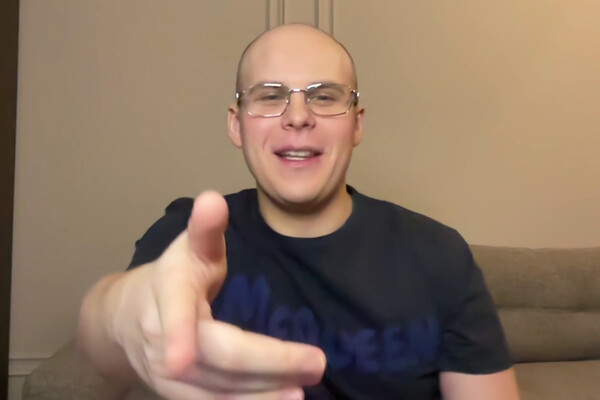

In [113]:
from IPython.display import Image
Image('https://img.gazeta.ru/files3/159/22603159/tox0-pic_32ratio_600x400-600x400-66030.jpg')